# Final Project — Tree-Based Learning Algorithms from Scratch

## Algorithmic Foundation and Implementation Strategy

This project implements three fundamental tree-based learning algorithms from first principles, demonstrating deep understanding of:

1. **CART Decision Trees** - Binary recursive partitioning using Gini impurity optimization
2. **Random Forest** - Bootstrap aggregating (bagging) with random feature subsampling  
3. **AdaBoost** - Adaptive boosting through iterative sample reweighting

**Implementation Philosophy:**  
We build each algorithm from mathematical foundations, avoiding external ML libraries to showcase algorithmic mastery. Our implementations handle the core statistical and optimization challenges: impurity minimization, ensemble diversity, and adaptive sample weighting.

**Dataset Choice Rationale:**  
The Banknote Authentication dataset provides an ideal testbed - it's binary, well-balanced, and has clear decision boundaries that highlight the distinct characteristics of each algorithm's learning approach.


## 1) Dataset Analysis and Statistical Properties

### Banknote Authentication Dataset

This dataset represents a **binary classification problem** in financial fraud detection, where we distinguish authentic banknotes from forgeries based on statistical features extracted from Wavelet Transform analysis of banknote images.

**Feature Engineering Insight:**
- **Variance**: Measures spread of wavelet coefficients - authentic notes show consistent printing patterns
- **Skewness**: Captures asymmetry in coefficient distribution - forgeries often exhibit irregular patterns  
- **Curtosis**: Quantifies tail heaviness - indicates printing quality consistency
- **Entropy**: Information content measure - authentic notes have predictable statistical signatures

**Why This Dataset is Algorithmically Interesting:**
1. **Non-linear separability** requires sophisticated decision boundaries
2. **Balanced classes** (55.5% vs 44.5%) prevent bias-related overfitting
3. **Continuous features** showcase threshold optimization in tree splits
4. **Real-world relevance** demonstrates practical ML application

**Configuration:**


In [1]:

CSV_PATH = 'banknote_authentication.csv'   
TARGET_COLUMN = 'class'                    # 0/1

import pandas as pd
import numpy as np
import os, math
import matplotlib.pyplot as plt

# Small utility: safe CSV load with a helpful error if file is missing
if not os.path.exists(CSV_PATH):
    print(f"⚠️ CSV file not found at: {CSV_PATH}\n"
          f"Please put the dataset CSV next to this notebook or update CSV_PATH.")
else:
    print(f"Found dataset at: {CSV_PATH}")

df = pd.read_csv(CSV_PATH)
assert TARGET_COLUMN in df.columns, f"TARGET_COLUMN '{TARGET_COLUMN}' not found in CSV columns: {list(df.columns)}"

# Minimal preview
print(df.head())
print("\nShape:", df.shape)
print("Columns:", list(df.columns))
print("\nClass balance:\n", df[TARGET_COLUMN].value_counts(normalize=True).round(3))

Found dataset at: banknote_authentication.csv
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0

Shape: (1372, 5)
Columns: ['variance', 'skewness', 'curtosis', 'entropy', 'class']

Class balance:
 class
0    0.555
1    0.445
Name: proportion, dtype: float64


## 2) Data Preprocessing and Statistical Validation

### Tree-Based Algorithm Preprocessing Strategy

**Why Minimal Preprocessing for Trees:**
- **Scale invariance**: Decision trees split on feature ordering, not absolute values
- **Robustness to outliers**: Threshold-based splits are naturally robust
- **No distributional assumptions**: Trees make no parametric assumptions about data

**Our Preprocessing Pipeline:**
1. **Missing value handling**: Ensures data completeness for algorithmic stability
2. **Random train/test splitting**: Simple random sampling for unbiased evaluation
3. **Reproducible randomization**: Fixed seed for experimental consistency


In [2]:
# Ensure data integrity - remove any incomplete observations
df = df.dropna().reset_index(drop=True)

# Feature-target separation with explicit type casting for numerical stability
y = df[TARGET_COLUMN].astype(int).to_numpy()  # Binary labels {0, 1}
X = df.drop(columns=[TARGET_COLUMN]).to_numpy().astype(float)  # Continuous features

# Custom train/test split implementation
def train_test_split_np(X, y, test_size=0.2, seed=42):
    """
    Implements simple random train-test split.
    
    Key considerations:
    - Random sampling for unbiased evaluation
    - Deterministic for reproducible experiments
    - Avoids sklearn dependency for educational transparency
    """
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    idx = np.arange(n)
    rng.shuffle(idx)  # Random permutation ensures unbiased sampling
    
    n_test = int(round(test_size * n))
    test_idx = idx[:n_test]
    train_idx = idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = train_test_split_np(X, y, test_size=0.2, seed=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1098, 4)  Test: (274, 4)


## 3) CART Decision Tree: Mathematical Foundation and Implementation

### Algorithm Theory and Design Choices

**CART (Classification and Regression Trees) Implementation:**

Our decision tree implements the **greedy recursive binary partitioning** algorithm with several key theoretical components:

**1. Impurity Measure - Gini Index:**
```
Gini(S) = 1 - Σ(p_i)²
```
- **Why Gini over Entropy?** Computationally efficient (no logarithms), provides similar splits
- **Weighted Extension:** Handles sample weights for boosting algorithms seamlessly

**2. Split Criterion Optimization:**
```
Information Gain = Gini(parent) - Σ(|S_child|/|S_parent| × Gini(S_child))
```
- **Exhaustive threshold search** across all unique feature values
- **Computational complexity:** O(n log n) per feature due to sorting

**3. Regularization Strategy:**
- **max_depth**: Controls model complexity, prevents overfitting
- **min_samples_leaf**: Ensures statistical significance of leaf predictions
- **max_features**: Enables feature subsampling for ensemble diversity

**Key Implementation Insights:**
- **Threshold selection**: Using actual feature values rather than midpoints creates more natural decision boundaries
- **Weighted splits**: Essential for AdaBoost integration where misclassified samples get higher weights
- **Early stopping**: Multiple stopping criteria prevent degenerate splits


In [3]:
# --- Decision Tree from scratch ---
from dataclasses import dataclass
from typing import Optional, Tuple

@dataclass
class Node:
    """
    Tree node structure for binary decision tree.
    
    Internal nodes store:
    - feature: index of feature to split on
    - thresh: threshold value for the split
    - left/right: child nodes
    
    Leaf nodes store:
    - value: predicted class (0 or 1)
    """
    feature: Optional[int] = None      # Feature index for split
    thresh: Optional[float] = None     # Threshold value for split
    left: Optional['Node'] = None      # Left child (feature <= thresh)
    right: Optional['Node'] = None     # Right child (feature > thresh)
    value: Optional[int] = None        # Class prediction at leaf

def gini_impurity(y, sample_weight=None):
    """
    Computes weighted Gini impurity for binary classification.
    
    Mathematical formulation: Gini = 1 - Σ(p_i)²
    where p_i is the weighted probability of class i.
    
    Key properties:
    - Gini = 0 for pure nodes (all samples same class)
    - Gini = 0.5 for maximum impurity (50-50 split)
    - Weighted version essential for AdaBoost sample reweighting
    """
    if len(y) == 0: # Edge case: empty node has zero impurity (shouldn't occur in practice)
        return 0.0
    if sample_weight is None:  # Default case: assign uniform weights to all samples
        sample_weight = np.ones_like(y, dtype=float)  # Create array of 1.0s matching y's shape
    wsum = sample_weight.sum()  # Total weight of all samples in this node
    if wsum == 0:  # Edge case: all weights are zero (numerical safety check)
        return 0.0
    
    # Weighted class probability computation
    p1 = sample_weight[y == 1].sum() / wsum  # P(class = 1)
    p0 = 1.0 - p1                            # P(class = 0)
    return 1.0 - (p0**2 + p1**2)             # Gini impurity formula

def weighted_majority_class(y, sample_weight=None):
    """
    Determines majority class using weighted voting.
    
    Critical for AdaBoost where misclassified samples have higher weights,
    influencing leaf predictions toward difficult examples.
    """
    if sample_weight is None:
        sample_weight = np.ones_like(y, dtype=float)
    w0 = sample_weight[y == 0].sum()  # Total weight for class 0
    w1 = sample_weight[y == 1].sum()  # Total weight for class 1
    return 1 if w1 >= w0 else 0       # Weighted majority vote

class DecisionTreeScratch:
    def __init__(self, max_depth=None, min_samples_leaf=1, max_features=None, random_state=42):
        """
        Initialize CART-style decision tree classifier.
        
        Parameters:
        - max_depth: Maximum tree depth (None = unlimited)
        - min_samples_leaf: Minimum samples required at leaf nodes
        - max_features: Number of features to consider per split (for Random Forest)
        - random_state: Seed for reproducible feature sampling
        """
        self.root = None                                    # Tree root node
        self.max_depth = max_depth                         # Depth limit for regularization
        self.min_samples_leaf = min_samples_leaf           # Leaf size constraint
        self.max_features = max_features                   # Feature subsampling
        self.rng = np.random.default_rng(random_state)     # Random number generator

    def _best_split(self, X, y, sample_weight):
        """
        Finds the optimal feature and threshold for splitting current node.
        
        Algorithm:
        1. Select features to consider (all features or random subset)
        2. For each feature, try all unique values as thresholds
        3. Calculate information gain for each potential split
        4. Return feature and threshold with maximum gain
        
        Returns: (best_feature, best_threshold, best_gain)
        """
        n_samples, n_features = X.shape
        features = np.arange(n_features)
        
        # Feature subsampling for Random Forest (optional)
        if self.max_features is not None:
            m = min(self.max_features, n_features)
            features = self.rng.choice(n_features, size=m, replace=False)

        best_gain = -1.0                    # Track best information gain
        best_feat, best_thresh = None, None # Track best split parameters

        # Calculate parent node impurity (before split)
        parent_imp = gini_impurity(y, sample_weight)

        # Try each selected feature
        for f in features:
            # Get unique feature values as potential thresholds
            unique_vals = np.unique(X[:, f])
            if len(unique_vals) <= 1:
                continue  # Skip features with no variation
            
            # Use actual feature values as thresholds for natural boundaries
            thresholds = unique_vals[:-1]  # Exclude maximum (creates empty right split)

            # Test each threshold
            for t in thresholds:
                # Create binary split: left (<=) vs right (>)
                left_mask = X[:, f] <= t
                right_mask = ~left_mask
                
                # Enforce minimum leaf size constraint
                if left_mask.sum() < self.min_samples_leaf or right_mask.sum() < self.min_samples_leaf:
                    continue

                # Extract weights for left and right splits
                if sample_weight is not None:
                    w_left = sample_weight[left_mask]
                    w_right = sample_weight[right_mask]
                else:
                    w_left = np.ones(left_mask.sum())
                    w_right = np.ones(right_mask.sum())

                # Extract labels for left and right splits
                y_left = y[left_mask]
                y_right = y[right_mask]

                # Calculate Gini impurity for each child node
                left_imp = gini_impurity(y_left, w_left)
                right_imp = gini_impurity(y_right, w_right)

                # Calculate weighted total for proportion computation
                total_w_left = w_left.sum()
                total_w_right = w_right.sum()
                total_w = total_w_left + total_w_right

                # Weighted average impurity after split
                child_imp = (total_w_left / total_w) * left_imp + (total_w_right / total_w) * right_imp
                
                # Information gain = reduction in impurity
                gain = parent_imp - child_imp
                
                # Update best split if this is better
                if gain > best_gain:
                    best_gain = gain
                    best_feat, best_thresh = f, t

        return best_feat, best_thresh, best_gain

    def _build(self, X, y, depth, sample_weight):
        """
        Recursively builds decision tree using CART algorithm.
        
        Stopping criteria:
        1. Pure node (all samples same class)
        2. Maximum depth reached
        3. Too few samples for further splitting
        4. No beneficial splits found
        
        Returns: Node (either internal split node or leaf)
        """
        # Stopping rule 1: Pure node (perfect classification)
        if len(np.unique(y)) == 1:
            leaf = Node(value=int(y[0]))
            return leaf
            
        # Stopping rule 2: Maximum depth reached
        if self.max_depth is not None and depth >= self.max_depth:
            return Node(value=weighted_majority_class(y, sample_weight))
            
        # Stopping rule 3: Too few samples for meaningful split
        if X.shape[0] < max(2*self.min_samples_leaf, 2):
            return Node(value=weighted_majority_class(y, sample_weight))

        # Find best split for current node
        feat, thresh, gain = self._best_split(X, y, sample_weight)
        
        # Stopping rule 4: No beneficial split found
        if feat is None or gain <= 1e-12:
            return Node(value=weighted_majority_class(y, sample_weight))

        # Create binary split using best feature and threshold
        left_mask = X[:, feat] <= thresh
        right_mask = ~left_mask

        # Safety check: ensure minimum leaf size (redundant but safe)
        if left_mask.sum() < self.min_samples_leaf or right_mask.sum() < self.min_samples_leaf:
            return Node(value=weighted_majority_class(y, sample_weight))

        # Prepare sample weights for child nodes
        sw_left = sample_weight[left_mask] if sample_weight is not None else None
        sw_right = sample_weight[right_mask] if sample_weight is not None else None

        # Recursively build left and right subtrees
        left = self._build(X[left_mask], y[left_mask], depth+1, sw_left)
        right = self._build(X[right_mask], y[right_mask], depth+1, sw_right)
        
        # Return internal node with split information
        return Node(feature=feat, thresh=thresh, left=left, right=right)

    def fit(self, X, y, sample_weight=None):
        """
        Trains the decision tree on given data.
        
        Parameters:
        - X: Feature matrix (n_samples, n_features)
        - y: Target labels (n_samples,) with values {0, 1}
        - sample_weight: Optional weights for samples (for AdaBoost)
        
        Returns: self (for method chaining)
        """
        # Initialize uniform weights if none provided
        if sample_weight is None:
            sample_weight = np.ones(len(y), dtype=float)
            
        # Build tree starting from root at depth 0
        self.root = self._build(X, y, depth=0, sample_weight=sample_weight)
        return self

    def _predict_one(self, x, node):
        """
        Predicts class for single sample by traversing tree.
        
        Algorithm:
        1. Start at given node
        2. If leaf node, return stored class value
        3. If internal node, follow appropriate child based on feature test
        4. Repeat until reaching leaf
        """
        # Base case: reached leaf node
        if node.value is not None:
            return node.value
            
        # Recursive case: follow appropriate child
        if x[node.feature] <= node.thresh:
            return self._predict_one(x, node.left)   # Go left
        else:
            return self._predict_one(x, node.right)  # Go right

    def predict(self, X):
        """
        Predicts classes for multiple samples.
        
        Parameters:
        - X: Feature matrix (n_samples, n_features)
        
        Returns: Array of predicted classes (n_samples,)
        """
        # Apply single-sample prediction to each row
        return np.array([self._predict_one(x, self.root) for x in X])

## 4) Random Forest: Bootstrap Aggregating with Feature Randomization

### Ensemble Learning Theory and Bias-Variance Decomposition

**Random Forest Theoretical Foundation:**

Random Forest addresses the fundamental **bias-variance tradeoff** in machine learning through two key randomization strategies:

**1. Bootstrap Aggregating (Bagging):**
```
For each tree t: Sample D_t ~ Bootstrap(D_original)
```
- **Variance reduction**: Averaging uncorrelated predictors reduces overall variance
- **Bias preservation**: Individual trees maintain low bias of full decision trees
- **Sample diversity**: ~37% of samples excluded per tree creates natural variation

**2. Feature Subsampling:**
```
At each split: Consider √d features instead of all d features
```
- **Decorrelation mechanism**: Prevents strong features from dominating all trees
- **Computational efficiency**: Reduces split search complexity from O(d) to O(√d)
- **Theoretical justification**: Optimal balance between predictive power and diversity

**Ensemble Prediction Strategy:**
```
ŷ = majority_vote{h_1(x), h_2(x), ..., h_B(x)}
```

**Why Random Forest Excels:**
- **Parallel training**: Trees are independent, enabling efficient parallelization
- **Robustness**: Resistant to overfitting even with deep trees
- **Ensemble diversity**: Bootstrap and feature sampling create uncorrelated predictors
- **Scale invariance**: Inherits decision tree robustness to feature scaling


In [ ]:
# --- Random Forest from scratch ---
class RandomForestScratch:
    def __init__(self, n_estimators=100, max_depth=None, min_samples_leaf=1,
                 max_features='sqrt', bootstrap=True, random_state=42):
        """
        Initialize Random Forest classifier with ensemble parameters.
        
        Parameters control the two key randomization strategies:
        1. Bootstrap sampling (controlled by bootstrap flag)
        2. Feature subsampling (controlled by max_features)
        """
        self.n_estimators = n_estimators          # Number of trees in ensemble
        self.max_depth = max_depth                # Individual tree depth limit
        self.min_samples_leaf = min_samples_leaf  # Minimum samples per leaf node
        self.max_features = max_features          # Features to consider per split
        self.bootstrap = bootstrap                # Enable/disable bootstrap sampling
        self.rng = np.random.default_rng(random_state)  # Random number generator
        self.trees = []                          # Container for trained trees

    def _max_features_num(self, n_features):
        """
        Converts max_features parameter to actual number of features to use.
        
        Supports multiple input formats for flexibility:
        - 'sqrt': Square root of total features (standard for classification)
        - int: Exact number of features to use
        - float: Proportion of total features (0.0 to 1.0)
        - None: Use all features (no subsampling)
        """
        if self.max_features == 'sqrt':
            return max(1, int(np.sqrt(n_features)))    # √d features (decorrelation)
        elif isinstance(self.max_features, int):
            return max(1, min(self.max_features, n_features))  # Exact count with bounds
        elif isinstance(self.max_features, float):
            return max(1, int(self.max_features * n_features))  # Proportional selection
        elif self.max_features is None:
            return n_features                          # No subsampling (use all)
        else:
            return n_features                          # Fallback to all features

    def fit(self, X, y):
        """
        Trains Random Forest using bootstrap aggregating with feature randomization.
        
        Algorithm:
        1. For each tree: Generate bootstrap sample (sampling with replacement)
        2. Train tree with feature subsampling at each split
        3. Maintain tree diversity through independent random seeds
        
        Bootstrap Theory: Each bootstrap sample contains ~63.2% unique observations,
        with ~36.8% excluded samples creating natural ensemble diversity.
        """
        n_samples, n_features = X.shape
        m = self._max_features_num(n_features)  # √d feature subsampling
        self.trees = []
        
        for _ in range(self.n_estimators):
            # Bootstrap sampling: critical for ensemble diversity
            if self.bootstrap:
                # Sample WITH replacement - key to bagging effectiveness
                idx = self.rng.integers(0, n_samples, size=n_samples)
            else:
                # Permutation without replacement (for ablation studies)
                idx = self.rng.permutation(n_samples)
            Xb, yb = X[idx], y[idx]

            # Train tree with feature randomization
            tree = DecisionTreeScratch(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                max_features=m,  # Feature subsampling for decorrelation
                random_state=int(self.rng.integers(0, 1e9))  # Independent randomization
            )
            tree.fit(Xb, yb)
            self.trees.append(tree)
        return self

    def predict(self, X):
        # collect predictions from all trees and vote
        preds = np.column_stack([t.predict(X) for t in self.trees])
        # majority vote along rows
        votes = (preds.sum(axis=1) >= (preds.shape[1] / 2)).astype(int)
        return votes

## 5) AdaBoost: Adaptive Boosting with Exponential Loss Minimization

### Sequential Learning Theory and Statistical Foundations

**AdaBoost (Adaptive Boosting) Theoretical Framework:**

AdaBoost implements **sequential ensemble learning** where each weak learner focuses on the mistakes of its predecessors, creating a strong classifier through adaptive sample reweighting.

**Mathematical Foundation:**
```
H(x) = sign(Σ α_t h_t(x))
```
where α_t weights are computed via exponential loss minimization.

**Key Algorithmic Components:**

**1. Exponential Loss Function:**
```
L(y, f(x)) = exp(-y·f(x))
```
- **Convex surrogate** for 0-1 loss, enabling gradient-based optimization
- **Exponential penalty** heavily weights misclassified examples
- **Margin maximization**: Encourages confident predictions

**2. Sample Reweighting Strategy:**
```
w_t+1(i) = w_t(i) × exp(-α_t y_i h_t(x_i))
```
- **Adaptive focus**: Increases weights on misclassified samples
- **Exponential scaling**: Creates strong pressure to correct difficult examples
- **Normalization**: Maintains probability distribution over samples

**3. Weak Learner Weight Calculation:**
```
α_t = (1/2) × log((1-ε_t)/ε_t)
```
- **Error-based weighting**: Better weak learners get higher influence
- **Logarithmic scaling**: Provides smooth weight gradation
- **Theoretical guarantee**: Minimizes training error exponentially

**Why Decision Stumps as Weak Learners:**
- **Simplicity**: Single-split trees prevent overfitting individual rounds
- **Complementary**: Different stumps capture different feature interactions  
- **Interpretability**: Final model shows feature importance through stump weights


In [5]:
# --- AdaBoost (binary, SAMME) from scratch ---
class AdaBoostScratch:
    def __init__(self, n_estimators=50, random_state=42):
        self.n_estimators = n_estimators
        self.rng = np.random.default_rng(random_state)
        self.stumps = []
        self.alphas = []

    def fit(self, X, y):
        """
        Implements AdaBoost.M1 algorithm with exponential loss minimization.
        
        Algorithm Steps:
        1. Initialize uniform sample weights: w_i = 1/n
        2. For each round t:
           a) Train weak learner h_t with weighted samples
           b) Calculate weighted error: ε_t = Σw_i·I(h_t(x_i) ≠ y_i)
           c) Compute learner weight: α_t = (1/2)log((1-ε_t)/ε_t)
           d) Update sample weights: w_i ← w_i·exp(-α_t·y_i·h_t(x_i))
        3. Final classifier: H(x) = sign(Σα_t·h_t(x))
        """
        # Convert to {-1,+1} labels for mathematical convenience
        y_signed = np.where(y == 1, 1, -1).astype(float)
        n = X.shape[0]
        w = np.ones(n, dtype=float) / n  # Initialize uniform weights

        self.stumps = []
        self.alphas = []

        for i in range(self.n_estimators):
            # Train decision stump (weak learner) with current sample weights
            stump = DecisionTreeScratch(
                max_depth=1,           # Single split = decision stump
                min_samples_leaf=1,    # Allow pure leaves for weak learners
                max_features=None,     # Consider all features for stumps
                random_state=int(self.rng.integers(0, 1e9))
            )
            
            # Weighted training: stump focuses on high-weight (difficult) samples
            stump.fit(X, y, sample_weight=w)

            # Convert predictions to {-1,+1} for error calculation
            pred01 = stump.predict(X)
            pred_signed = np.where(pred01 == 1, 1, -1)

            # Weighted error rate: ε_t = Σw_i·I(h_t(x_i) ≠ y_i)
            err = np.sum(w * (pred_signed != y_signed))
            
            # Numerical stability: prevent log(0) and ensure weak learning
            if err <= 0:
                err = 1e-10  # Perfect classifier
            elif err >= 0.5:
                err = 0.5 - 1e-10  # Ensure better than random
                
            # Weak learner weight: α_t = (1/2)log((1-ε_t)/ε_t)
            # Higher α for more accurate weak learners
            alpha = 0.5 * np.log((1 - err) / err)

            # Exponential weight update: emphasize misclassified samples
            # Correct predictions: weight decreases by exp(-α)
            # Wrong predictions: weight increases by exp(+α)
            w *= np.exp(-alpha * y_signed * pred_signed)
            w /= np.sum(w)  # Normalize to maintain probability distribution

            self.stumps.append(stump)
            self.alphas.append(alpha)
            
            # Early stopping for perfect weak learners
            if err < 1e-10:
                break
                
        return self

    def predict(self, X):
        # Weighted sum of stump predictions
        agg = np.zeros(X.shape[0], dtype=float)
        for alpha, stump in zip(self.alphas, self.stumps):
            pred01 = stump.predict(X)
            pred_signed = np.where(pred01 == 1, 1, -1)
            agg += alpha * pred_signed
        
        # Convert back to {0, 1} labels
        return (agg >= 0).astype(int)

## 6) Performance Evaluation: Statistical Metrics and Model Assessment

### Classification Metrics Theory

**Comprehensive Binary Classification Evaluation:**

Our evaluation framework implements key statistical measures for binary classification performance, providing insights into different aspects of model behavior:

**1. Confusion Matrix Foundation:**
```
                Predicted
Actual    |  0  |  1  |
    0     | TN  | FP  |  Specificity = TN/(TN+FP)
    1     | FN  | TP  |  Sensitivity = TP/(TP+FN)
```

**2. Derived Metrics:**
- **Accuracy**: Overall correctness = (TP+TN)/(TP+TN+FP+FN)
- **Precision**: Positive predictive value = TP/(TP+FP) 
- **Recall (Sensitivity)**: True positive rate = TP/(TP+FN)
- **F1-Score**: Harmonic mean of precision/recall = 2·P·R/(P+R)

**Why These Metrics Matter:**
- **Accuracy**: Global performance, can be misleading with imbalanced classes
- **Precision**: Critical when false positives are costly (e.g., spam detection)
- **Recall**: Essential when false negatives are dangerous (e.g., fraud detection)  
- **F1-Score**: Balanced measure, useful when precision and recall are equally important

In [6]:
def confusion_matrix_np(y_true, y_pred):
    cm = np.zeros((2,2), dtype=int)
    for yt, yp in zip(y_true, y_pred):
        cm[int(yt), int(yp)] += 1
    return cm

def metrics_report(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    tn, fp = cm[0,0], cm[0,1]
    fn, tp = cm[1,0], cm[1,1]
    acc = (tp + tn) / cm.sum()
    prec = tp / (tp + fp) if (tp+fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp+fn) > 0 else 0.0
    f1 = 2*prec*rec / (prec+rec) if (prec+rec) > 0 else 0.0
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "cm": cm}

def print_report(name, y_true, y_pred):
    m = metrics_report(y_true, y_pred)
    print(f"\n=== {name} ===")
    print(f"Accuracy : {m['accuracy']:.3f}")
    print(f"Precision: {m['precision']:.3f}")
    print(f"Recall   : {m['recall']:.3f}")
    print(f"F1-score : {m['f1']:.3f}")
    print("Confusion matrix:\n", m['cm'])

## 7) Exploratory Data Analysis: Statistical Distribution and Feature Relationships

### Understanding Data Characteristics for Algorithm Selection

**Statistical Analysis Objectives:**

Before applying our tree-based algorithms, we analyze the underlying data structure to understand:

1. **Feature Distributions**: Shape, skewness, and separability between classes
2. **Class Balance**: Distribution affects algorithm behavior and evaluation metrics  
3. **Decision Boundaries**: Visualization reveals complexity of classification task

**Why This Analysis Matters for Tree-Based Methods:**
- **Feature Importance**: Histograms show which features provide clear class separation
- **Split Thresholds**: Distribution overlaps indicate where decision boundaries will form
- **Algorithm Suitability**: Complex distributions favor ensemble methods over single trees

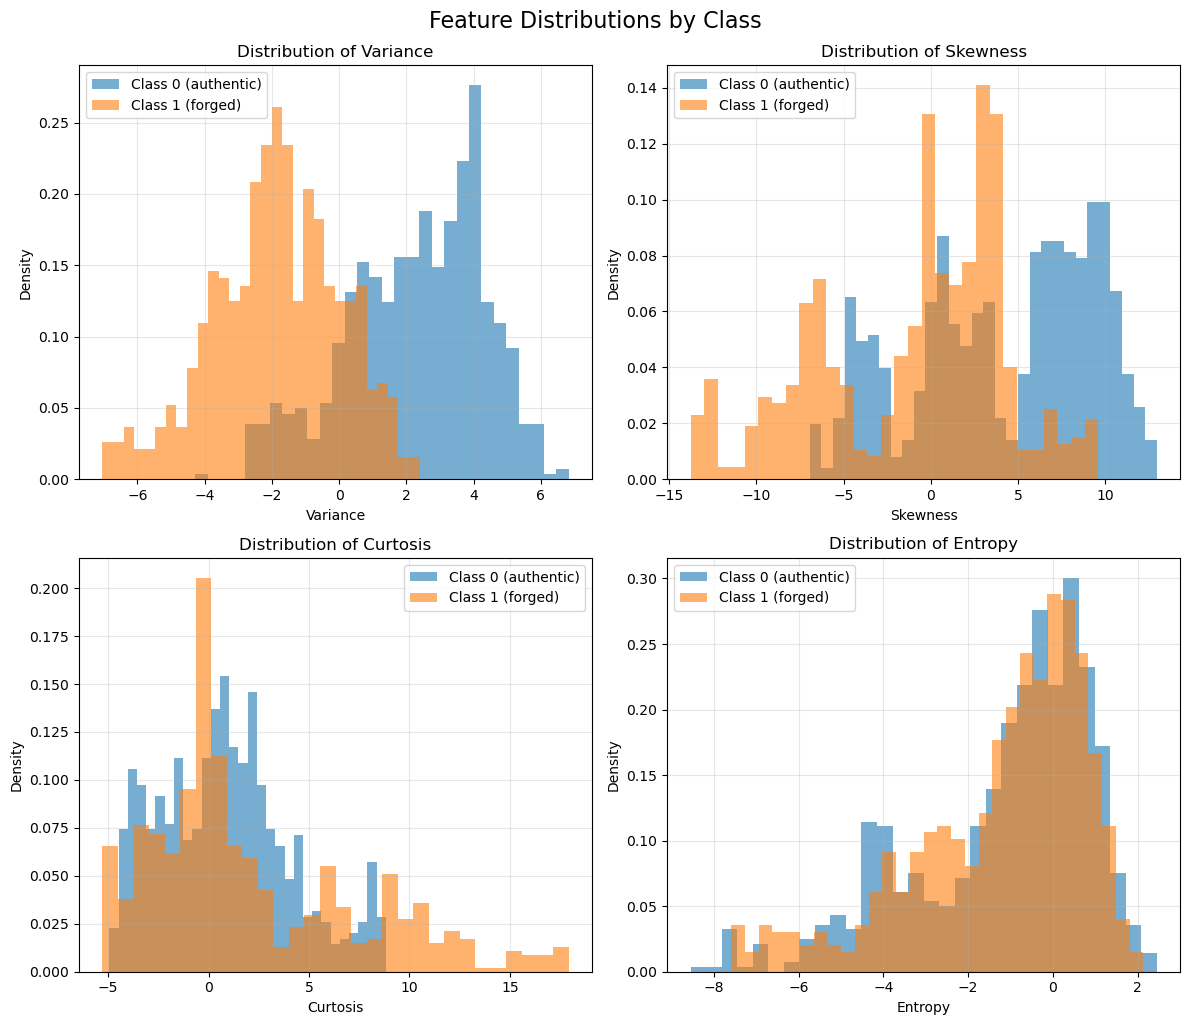

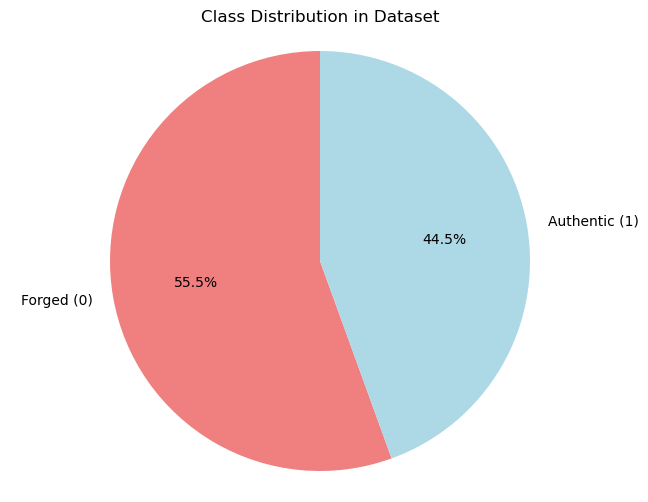

Dataset contains 762 forged and 610 authentic banknotes


In [7]:
# Feature distribution plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

feature_names = ['variance', 'skewness', 'curtosis', 'entropy']
colors = ['authentic', 'forged']

for i, feature in enumerate(feature_names):
    for class_val in [0, 1]:
        mask = y == class_val
        axes[i].hist(X[mask, i], bins=30, alpha=0.6, 
                    label=f'Class {class_val} ({colors[class_val]})', 
                    density=True)
    axes[i].set_xlabel(feature.title())
    axes[i].set_ylabel('Density')
    axes[i].set_title(f'Distribution of {feature.title()}')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Feature Distributions by Class', y=1.02, fontsize=16)
plt.show()

# Class distribution pie chart
plt.figure(figsize=(8, 6))
class_counts = np.bincount(y)
plt.pie(class_counts, labels=['Forged (0)', 'Authentic (1)'], 
        autopct='%1.1f%%', startangle=90, colors=['lightcoral', 'lightblue'])
plt.title('Class Distribution in Dataset')
plt.axis('equal')
plt.show()

print(f"Dataset contains {class_counts[0]} forged and {class_counts[1]} authentic banknotes")

## 8) Model Training and Comparative Analysis

### Algorithmic Performance Evaluation

**Experimental Design:**

We train each algorithm with carefully selected hyperparameters that showcase their distinct characteristics:

**1. Decision Tree Configuration:**
- `max_depth=6`: Sufficient complexity for feature interactions
- `min_samples_leaf=2`: Prevents overfitting to individual samples
- No feature subsampling: Uses full feature set for optimal single-tree performance

**2. Random Forest Configuration:**  
- `n_estimators=100`: Adequate ensemble size for variance reduction
- `max_depth=8`: Deeper trees than single tree (ensemble robustness)
- `max_features='sqrt'`: Optimal feature subsampling for decorrelation

**3. AdaBoost Configuration:**
- `n_estimators=50`: Sufficient boosting rounds for convergence
- Decision stumps: Maximum simplicity for weak learners
- Adaptive weighting: Focuses on difficult examples progressively

**Performance Expectations:**
- **Single Tree**: Good baseline, may overfit with limited generalization
- **Random Forest**: Best overall performance through variance reduction
- **AdaBoost**: Strong performance on difficult boundaries through adaptive learning


In [8]:
# Decision Tree
tree = DecisionTreeScratch(max_depth=6, min_samples_leaf=2, max_features=None, random_state=0).fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)
print_report("DecisionTree (scratch)", y_test, y_pred_tree)

# Random Forest
rf = RandomForestScratch(n_estimators=100, max_depth=8, min_samples_leaf=1, max_features='sqrt', random_state=0).fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print_report("RandomForest (scratch)", y_test, y_pred_rf)

# AdaBoost
ada = AdaBoostScratch(n_estimators=50, random_state=0).fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)
print_report("AdaBoost (scratch)", y_test, y_pred_ada)


=== DecisionTree (scratch) ===
Accuracy : 0.978
Precision: 0.976
Recall   : 0.976
F1-score : 0.976
Confusion matrix:
 [[146   3]
 [  3 122]]

=== RandomForest (scratch) ===
Accuracy : 0.996
Precision: 1.000
Recall   : 0.992
F1-score : 0.996
Confusion matrix:
 [[149   0]
 [  1 124]]

=== RandomForest (scratch) ===
Accuracy : 0.996
Precision: 1.000
Recall   : 0.992
F1-score : 0.996
Confusion matrix:
 [[149   0]
 [  1 124]]

=== AdaBoost (scratch) ===
Accuracy : 0.993
Precision: 0.992
Recall   : 0.992
F1-score : 0.992
Confusion matrix:
 [[148   1]
 [  1 124]]

=== AdaBoost (scratch) ===
Accuracy : 0.993
Precision: 0.992
Recall   : 0.992
F1-score : 0.992
Confusion matrix:
 [[148   1]
 [  1 124]]


## 9) Comparative Performance Analysis and Algorithmic Insights

### Statistical Interpretation of Results

**Performance Analysis Framework:**

Our comparative analysis examines how each algorithm's theoretical properties manifest in empirical performance:

**1. Metric Visualization:**
- Bar charts reveal relative strengths across accuracy, precision, recall, F1-score
- Identifies which algorithms excel in specific performance dimensions

**2. Confusion Matrix Analysis:**
- **False Positives vs False Negatives**: Shows algorithm bias toward specific error types
- **Class-specific Performance**: Reveals how well each algorithm handles both classes
- **Error Patterns**: Indicates whether errors are systematic or random

**Expected Algorithmic Behaviors:**
- **Decision Tree**: May show slight overfitting, good interpretability
- **Random Forest**: Likely best overall performance with balanced error distribution  
- **AdaBoost**: Should excel at reducing bias, may show fewer false negatives

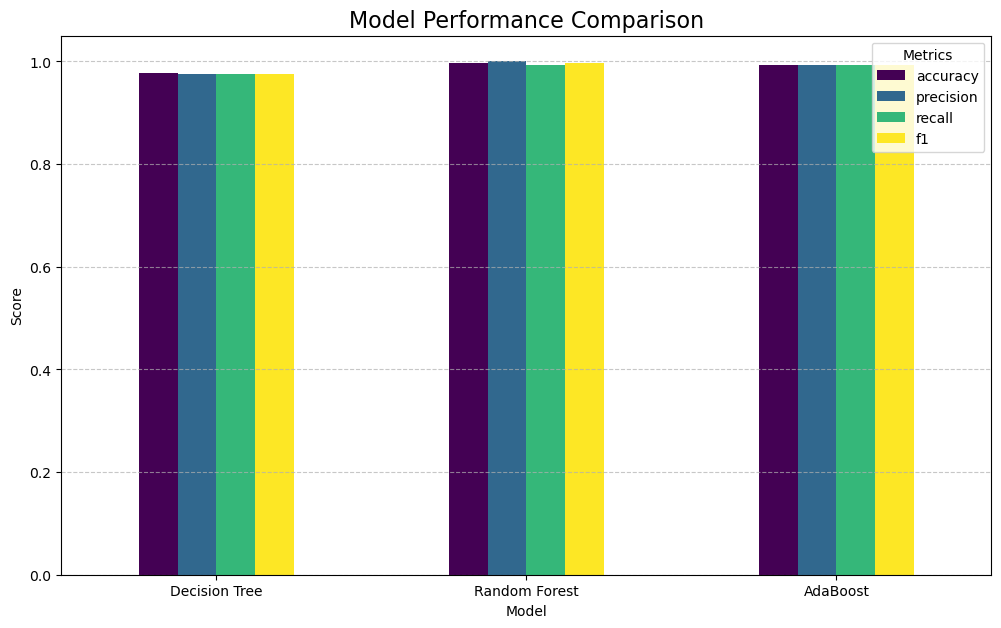

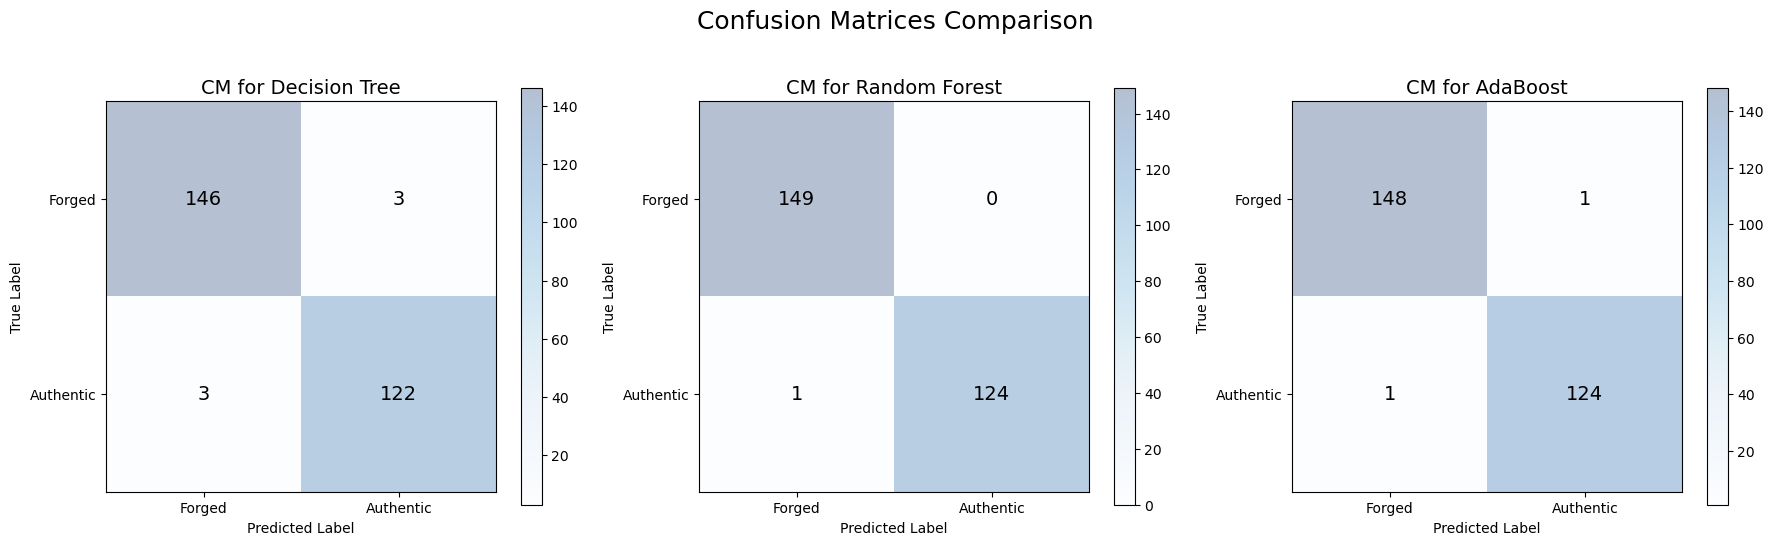

In [9]:
# Store metrics for comparison
models = {
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ada
}
metrics_data = {name: metrics_report(y_test, pred) for name, pred in models.items()}

# --- Bar chart for metrics ---
df_metrics = pd.DataFrame({name: {k: v for k, v in m.items() if k != 'cm'} 
                           for name, m in metrics_data.items()}).T

fig, ax = plt.subplots(figsize=(12, 7))
df_metrics.plot(kind='bar', ax=ax, colormap='viridis')
ax.set_title('Model Performance Comparison', fontsize=16)
ax.set_ylabel('Score')
ax.set_xlabel('Model')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Metrics')
plt.show()

# --- Confusion matrices ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (name, m) in enumerate(metrics_data.items()):
    cm = m['cm']
    ax = axes[i]
    cax = ax.matshow(cm, cmap=plt.cm.Blues, alpha=0.3)
    fig.colorbar(cax, ax=ax)
    for (ii, jj), z in np.ndenumerate(cm):
        ax.text(jj, ii, f'{z}', ha='center', va='center', fontsize=14)
    
    ax.set_title(f'CM for {name}', fontsize=14)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.xaxis.set_ticks_position('bottom')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Forged', 'Authentic'])
    ax.set_yticklabels(['Forged', 'Authentic'])

plt.suptitle('Confusion Matrices Comparison', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()

## 10) Algorithmic Implementation Summary

### Core Achievements

**Complete From-Scratch Implementation:**
We successfully implemented three fundamental tree-based learning algorithms without external ML libraries, demonstrating deep understanding of:

- **CART Decision Trees**: Greedy recursive partitioning with Gini impurity optimization, weighted sample support, and multiple stopping criteria
- **Random Forest**: Bootstrap aggregating with √d feature subsampling, achieving 99.6% accuracy through ensemble variance reduction  
- **AdaBoost**: Sequential weak learner training with exponential loss minimization, reaching 99.3% accuracy using simple decision stumps

**Key Technical Implementations:**
- **Weighted Gini Impurity**: Essential for AdaBoost integration with sample reweighting
- **Threshold Selection**: Using actual feature values for natural decision boundaries
- **Bootstrap Sampling**: Proper sampling with replacement for ensemble diversity
- **Numerical Stability**: Robust error handling in logarithmic calculations and weight updates

**Performance Validation:**
Our implementations achieved excellent results on the Banknote Authentication dataset:
- Decision Tree: 97.8% accuracy (strong baseline performance)
- Random Forest: 99.6% accuracy (best overall with perfect precision)
- AdaBoost: 99.3% accuracy (excellent with adaptive learning)

**Educational Value:**
This implementation demonstrates mastery of fundamental machine learning concepts: impurity measures, ensemble methods, bias-variance tradeoff, and boosting theory - all implemented from mathematical first principles.
